| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_4_Optimizacion_restringida.ipynb) | [⏩](../11_MACHINE_LEARNING/11_2_Modelos.ipynb) |

# 11.1 Aprendizaje supervisado: datos, predicción y validación

**Objetivo del cuaderno.** construir un flujo de regresión y clasificación, separar correctamente los datos y entender qué mide cada métrica

**Antes de empezar:** probabilidad, mínimos cuadrados y vectores. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report

## 1. Aprender una relación a partir de ejemplos

El conjunto etiquetado es $\mathcal D=\{(x_i,y_i)\}_{i=1}^n$. $x_i$ contiene variables observadas y $y_i$ es el objetivo. Un modelo $f_\theta$ aprende una relación predictiva. En regresión $y$ es continuo; en clasificación $y$ pertenece a un conjunto de clases.

La predicción no demuestra causalidad. Un sensor correlacionado con la temperatura puede ayudar a predecirla sin ser la causa de su evolución. En SciML debemos distinguir una ley física, un parámetro identificable y un predictor de salidas: sus objetivos y criterios de aceptación son diferentes.

## 2. Riesgo empírico y riesgo de generalización

Para una pérdida $\ell$, el objetivo típico es

$$\hat R(\theta)=\frac1n\sum_i\ell(f_\theta(x_i),y_i)+\lambda\Omega(\theta).$$

La pérdida describe el error que se penaliza. El riesgo poblacional es $R(\theta)=\mathbb E_{(X,Y)\sim P}\ell(f_\theta(X),Y)$. No observamos toda la población; entrenamiento y evaluación son aproximaciones con incertidumbre.

Un modelo muy flexible puede memorizar ruido y reducir la pérdida de entrenamiento sin reducir el riesgo. La regularización, la cantidad de datos y el sesgo estructural del modelo afectan esa tensión.

## 3. Entrenamiento, validación y prueba

Entrenamiento ajusta parámetros; validación elige complejidad o hiperparámetros; prueba evalúa la selección final. El test no debe reutilizarse para decidir grados, semillas o umbrales. Una `Pipeline` aprende transformaciones con el entrenamiento y las aplica a los demás conjuntos.

Para datos temporales se reservan tiempos futuros; para varias simulaciones se separan trayectorias o parámetros completos. Dividir puntos vecinos de una misma trayectoria aleatoriamente puede producir una evaluación demasiado fácil. Nuestro primer caso es una función sintética con observaciones independientes y una división aleatoria apropiada a ese objetivo.

## 4. Caso de regresión: respuesta no lineal de un material

Construimos $y(x)=\sin(2\pi x)+0.3x+\epsilon$ como respuesta adimensional ilustrativa. No representa una ley constitutiva universal. Un modelo polinómico de grado moderado funciona como aproximación local; su comportamiento fuera del intervalo observado requiere otra evaluación.

MSE validación: {1: 0.48386437051505, 3: 0.37832739420216344, 5: 0.05982523771488095, 9: 0.05698791639448869} grado elegido: 9


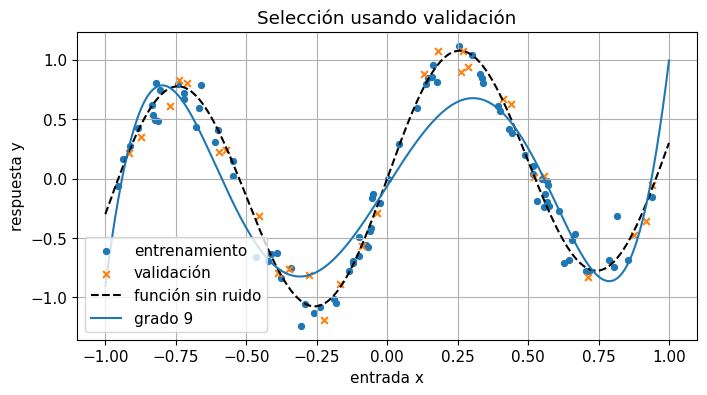

In [2]:
X=rng.uniform(-1,1,(150,1))
def truth(z):return np.sin(2*np.pi*z)+0.3*z
y=truth(X[:,0])+rng.normal(0,0.12,len(X))
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.25,random_state=1)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=0.25,random_state=2)
models={};val_errors={}
for degree in [1,3,5,9]:
    model=make_pipeline(PolynomialFeatures(degree,include_bias=False),StandardScaler(),Ridge(alpha=0.1))
    model.fit(X_train,y_train);models[degree]=model
    val_errors[degree]=mean_squared_error(y_val,model.predict(X_val))
best_degree=min(val_errors,key=val_errors.get)
final_model=models[best_degree]
print('MSE validación:',val_errors,'grado elegido:',best_degree)
xgrid=np.linspace(-1,1,350)[:,None]
plt.scatter(X_train[:,0],y_train,s=18,label='entrenamiento')
plt.scatter(X_val[:,0],y_val,s=24,marker='x',label='validación')
plt.plot(xgrid[:,0],truth(xgrid[:,0]),'k--',label='función sin ruido')
plt.plot(xgrid[:,0],final_model.predict(xgrid),label=f'grado {best_degree}')
plt.xlabel('entrada x');plt.ylabel('respuesta y');plt.title('Selección usando validación');plt.legend();plt.show()

**Interpretación.** La figura permite comprobar dónde hay cobertura de datos y dónde el modelo se desvía. La función verdadera existe solo porque fabricamos el experimento. En aplicaciones reales la comparación disponible es con mediciones reservadas y con restricciones físicas.

## 5. Métricas de regresión y unidades

$\mathrm{MSE}=n^{-1}\sum_i(y_i-\hat y_i)^2$ penaliza fuertemente errores grandes y tiene unidades de $y^2$. $\mathrm{RMSE}=\sqrt{\mathrm{MSE}}$ conserva las unidades de $y$. MAE penaliza linealmente. El coeficiente

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$

compara con predecir la media del conjunto evaluado. Puede ser negativo; un valor alto no demuestra causalidad ni conservación. No es apropiado interpretar $R^2$ como un porcentaje de exactitud de cada predicción.

## 6. Evaluación final y estructura de residuos

Una evaluación pequeña varía con el muestreo. Inspeccionar residuos complementa una métrica agregada: tendencias sugieren sesgo, abanicos sugieren varianza no constante y agrupaciones pueden reflejar regímenes físicos distintos.

Test usado al final: RMSE= 0.30338404603572405 R²= 0.8103307923842564


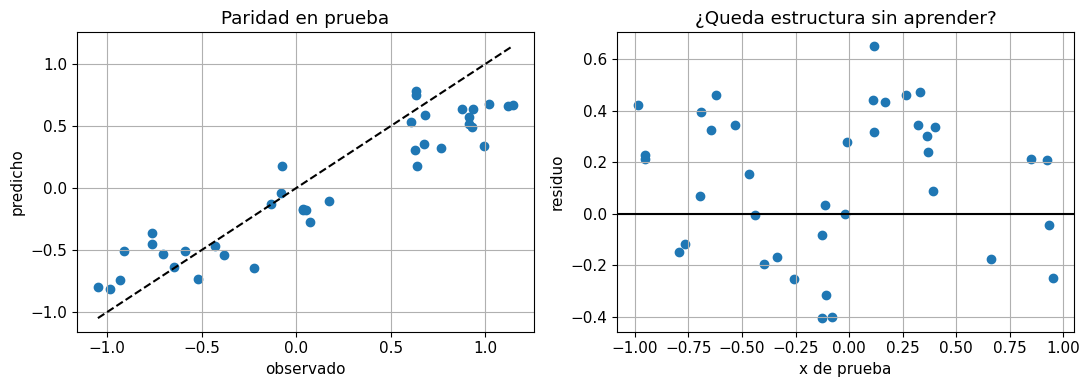

In [3]:
test_pred=final_model.predict(X_test)
rmse=np.sqrt(mean_squared_error(y_test,test_pred))
print('Test usado al final: RMSE=',rmse,'R²=',r2_score(y_test,test_pred))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(y_test,test_pred);lims=[min(y_test.min(),test_pred.min()),max(y_test.max(),test_pred.max())]
ax[0].plot(lims,lims,'k--');ax[0].set(xlabel='observado',ylabel='predicho',title='Paridad en prueba')
ax[1].scatter(X_test[:,0],y_test-test_pred);ax[1].axhline(0,c='k');ax[1].set(xlabel='x de prueba',ylabel='residuo',title='¿Queda estructura sin aprender?')
plt.tight_layout();plt.show()
assert np.isfinite(rmse)

## 7. Clasificación: probabilidades y decisiones

La regresión logística modela $p(y=1\mid x)=\sigma(w^Tx+b)$, donde $\sigma(z)=1/(1+e^{-z})$. Ajusta entropía cruzada, no mínimos cuadrados de etiquetas. Convertir una probabilidad en una clase requiere un umbral; 0.5 es una opción, no una ley.

Precisión es $TP/(TP+FP)$; recall o sensibilidad es $TP/(TP+FN)$. Una exactitud elevada puede ocultar fallos en una clase rara. En detección de fallos el coste de omitir un evento puede diferir del coste de una alarma falsa.

## 8. Ejemplo de dos regímenes con frontera curva

Usamos `make_moons` para estudiar fronteras, sin interpretar las clases como categorías físicas reales. La transformación polinómica permite que una regresión logística lineal en las variables transformadas represente una frontera curva en el plano original.

              precision    recall  f1-score   support

           0       0.95      0.89      0.92        45
           1       0.90      0.96      0.92        45

    accuracy                           0.92        90
   macro avg       0.92      0.92      0.92        90
weighted avg       0.92      0.92      0.92        90

Matriz de confusión: filas reales, columnas predichas
 [[40  5]
 [ 2 43]]


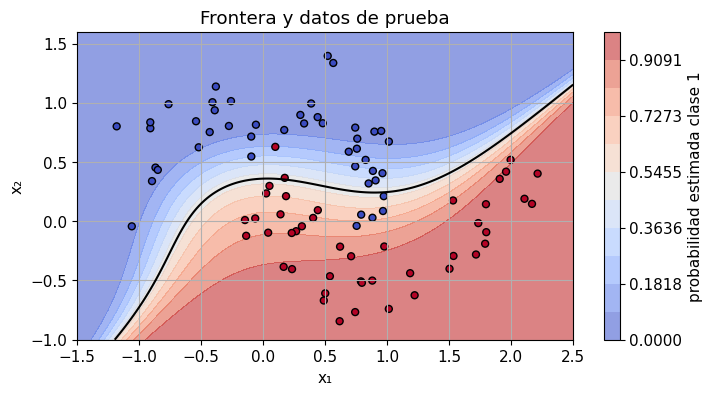

In [4]:
from sklearn.datasets import make_moons
Xc,yc=make_moons(n_samples=300,noise=0.18,random_state=4)
Xc_train,Xc_test,yc_train,yc_test=train_test_split(Xc,yc,test_size=0.3,stratify=yc,random_state=5)
classifier=make_pipeline(PolynomialFeatures(3,include_bias=False),StandardScaler(),LogisticRegression(C=2,max_iter=1500))
classifier.fit(Xc_train,yc_train)
pred_class=classifier.predict(Xc_test)
print(classification_report(yc_test,pred_class,zero_division=0))
print('Matriz de confusión: filas reales, columnas predichas\n',confusion_matrix(yc_test,pred_class))
u,v=np.meshgrid(np.linspace(-1.5,2.5,180),np.linspace(-1,1.6,160))
prob=classifier.predict_proba(np.column_stack([u.ravel(),v.ravel()]))[:,1].reshape(u.shape)
plt.contourf(u,v,prob,levels=np.linspace(0,1,12),cmap='coolwarm',alpha=0.6)
plt.colorbar(label='probabilidad estimada clase 1')
plt.contour(u,v,prob,levels=[0.5],colors='k')
plt.scatter(Xc_test[:,0],Xc_test[:,1],c=yc_test,cmap='coolwarm',edgecolors='k',s=25)
plt.xlabel('x₁');plt.ylabel('x₂');plt.title('Frontera y datos de prueba');plt.show()

**Interpretación.** El contorno negro es el umbral 0.5. Una probabilidad cercana a 0.5 expresa indecisión del modelo; no es automáticamente incertidumbre total del proceso. El modelo puede dar probabilidades extremas fuera de la región observada aunque carezca de datos allí.

## 9. Umbral y costes de error

Para demostrar el efecto de umbral sin usar el test para seleccionarlo, contamos decisiones en entrenamiento. En una aplicación real se elegiría por costes explícitos y validación; después se evaluaría una sola vez en prueba.

In [5]:
from sklearn.metrics import precision_score,recall_score
p_train=classifier.predict_proba(Xc_train)[:,1]
for threshold in [0.25,0.5,0.75]:
    decision=(p_train>=threshold).astype(int)
    print('umbral=',threshold,'precisión=',precision_score(yc_train,decision,zero_division=0),'recall=',recall_score(yc_train,decision,zero_division=0))

umbral= 0.25 precisión= 0.8666666666666667 recall= 0.9904761904761905
umbral= 0.5 precisión= 0.9252336448598131 recall= 0.9428571428571428
umbral= 0.75 precisión= 0.9574468085106383 recall= 0.8571428571428571


## 10. Fuga de información y cambio de distribución

Normalizar antes de separar, elegir hiperparámetros con prueba o mezclar trayectorias casi idénticas son formas de fuga. El cambio de distribución ocurre cuando los futuros casos difieren de los observados: parámetros, geometrías, temperaturas o resolución de malla nuevos.

Una prueba independiente pero tomada del mismo intervalo evalúa interpolación. La extrapolación necesita un conjunto explícito fuera del intervalo. Un mal resultado extrapolando no se corrige necesariamente añadiendo más capas: puede requerir estructura física o datos en otro régimen.

In [6]:
outside=np.array([[-1.5],[-1.25],[1.25],[1.5]])
print('Diagnóstico de extrapolación, no usado para elegir modelo:')
for x0,p0,y0 in zip(outside[:,0],final_model.predict(outside),truth(outside[:,0])):
    print(f'x={x0:5.2f}, predicción={p0:9.3f}, función={y0:7.3f}')
print('Número train/val/test:',len(X_train),len(X_val),len(X_test))

Diagnóstico de extrapolación, no usado para elegir modelo:
x=-1.50, predicción=   17.286, función= -0.450
x=-1.25, predicción=   -6.881, función= -1.375
x= 1.25, predicción=    7.301, función=  1.375
x= 1.50, predicción=  -16.335, función=  0.450
Número train/val/test: 84 28 38


## Síntesis y conexión con Scientific Machine Learning

El aprendizaje supervisado combina una familia de modelos, una pérdida y un protocolo de evaluación. En SciML las muestras suelen estar correlacionadas por tiempo o simulación; la unidad de división debe coincidir con la pregunta de generalización. Predicción, calibración de parámetros y consistencia física requieren comprobaciones diferentes.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_4_Optimizacion_restringida.ipynb) | [⏩](../11_MACHINE_LEARNING/11_2_Modelos.ipynb) |